**1. Загрузка данных и графики цен**

Данные загружены. Размер: (757, 2)
Ticker           EQNR       TSLA
Date                            
2019-12-31  12.613403  27.888666
2020-01-02  12.942832  28.684000
2020-01-03  12.980845  29.534000
2020-01-06  13.278599  30.102667
2020-01-07  13.126554  31.270666


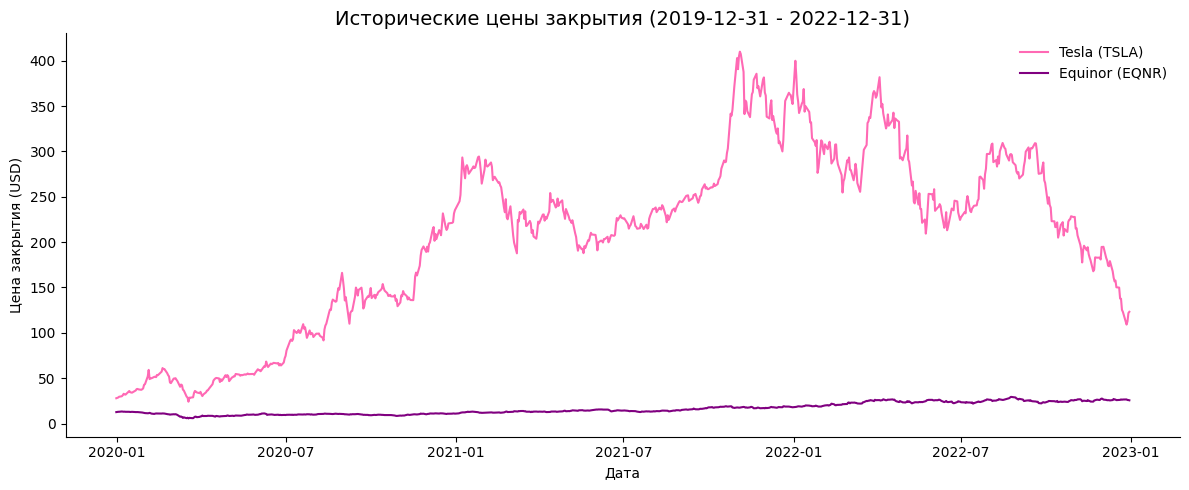

In [5]:
import warnings
warnings.simplefilter(action="ignore", category=(FutureWarning, DeprecationWarning))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error
import scipy.stats as stats
import matplotlib.dates as mdates

plt.style.use('default')
np.random.seed(42)

tickers = ['TSLA', 'EQNR']
start_date = '2019-12-31'
end_date = '2022-12-31'

data = yf.download(tickers, start=start_date, end=end_date, progress=False)['Close']

data = data.dropna()

print(f"Данные загружены. Размер: {data.shape}")
print(data.head())

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(data.index, data['TSLA'], label='Tesla (TSLA)', color='hotpink')
ax.plot(data.index, data['EQNR'], label='Equinor (EQNR)', color='purple')
ax.set_title('Исторические цены закрытия (2019-12-31 - 2022-12-31)', fontsize=14)
ax.set_xlabel('Дата')
ax.set_ylabel('Цена закрытия (USD)')
ax.legend(frameon=False)

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

Нам дано два временных ряда: Tesla демонстрирует значительный рост и высокую волатильность, особенно в 2020-2021 годах, за которым следует падение в 2022. Equinor показывает более стабильную динамику с меньшей амплитудой колебаний.

**2. Тест Дики-Фуллера (ADF) на стационарность**

In [8]:
def perform_adf_test(series, title):
    result = adfuller(series, autolag='AIC')
    print(f"ADF-тест для {title}:")
    print(f"ADF Statistic: {result[0]:.4f}")
    print(f"p-value: {result[1]:.4f}")
    print("Critical Values:")
    for key, value in result[4].items():
        print(f"   {key}: {value:.4f}")

    if result[1] < 0.05:
        print("Вывод: p-value < 0.05. Отвергаем H0. Ряд стационарен.")
    else:
        print("Вывод: p-value >= 0.05. Не можем отвергнуть H0. Ряд нестационарен.")
    print("\n")

perform_adf_test(data['TSLA'], "TSLA")
perform_adf_test(data['EQNR'], "EQNR")

ADF-тест для TSLA:
ADF Statistic: -1.8638
p-value: 0.3493
Critical Values:
   1%: -3.4391
   5%: -2.8654
   10%: -2.5688
Вывод: p-value >= 0.05. Не можем отвергнуть H0. Ряд нестационарен.


ADF-тест для EQNR:
ADF Statistic: -0.4418
p-value: 0.9029
Critical Values:
   1%: -3.4390
   5%: -2.8654
   10%: -2.5688
Вывод: p-value >= 0.05. Не можем отвергнуть H0. Ряд нестационарен.




Оба временных ряда являются нестационарными. Они содержат тренд или случайное блуждание, что типично для цен на акции.

**3. Расчет показателя Херста (H)**

In [11]:
def hurst(ts):
    lags = range(2, 100)
    tau = [np.var(np.subtract(ts[lag:], ts[:-lag])) for lag in lags]
    poly = np.polyfit(np.log(lags), np.log(tau), 1)
    return poly[0]/2.0

h_tsla = hurst(data['TSLA'].values)
h_eqnr = hurst(data['EQNR'].values)

print(f"Показатель Херста для TSLA: {h_tsla:.4f}")
print(f"Показатель Херста для EQNR: {h_eqnr:.4f}")

Показатель Херста для TSLA: 0.4626
Показатель Херста для EQNR: 0.3316


TSLA - Значение близко к 0.5, но все же ниже. Это указывает на слабую антиперсистентность (возврат к среднему). Ряд ведет себя почти как случайное блуждание, но с легкой тенденцией к развороту после больших отклонений.

EQNR - Значение существенно ниже 0.5, что говорит о сильной антиперсистентности. Временной ряд демонстрирует ярко выраженный возврат к среднему: за периодами роста с высокой вероятностью следуют периоды падения, и наоборот.

**4. Симуляция GBM**

TSLA: S0=123.18, mu=49.51%, sigma=72.18%
EQNR: S0=25.62, mu=23.62%, sigma=45.16%


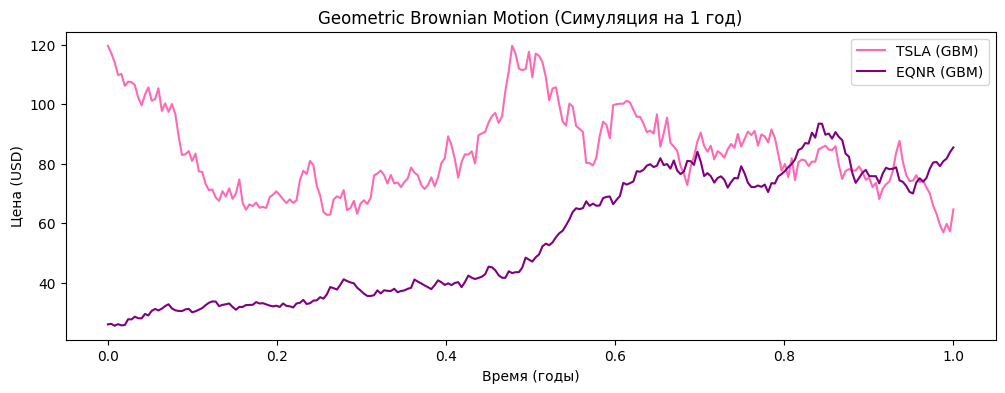

In [13]:
S0_tsla = data['TSLA'].iloc[-1]
log_ret_tsla = np.log(data['TSLA'] / data['TSLA'].shift(1)).dropna()
mu_tsla = log_ret_tsla.mean() * 252
sigma_tsla = log_ret_tsla.std() * np.sqrt(252)

T = 1
dt = 1/252
N = int(T/dt)
t = np.linspace(0, T, N)

dW_tsla = np.random.normal(0, np.sqrt(dt), N)
W_tsla = np.cumsum(dW_tsla)

S_tsla = S0_tsla * np.exp((mu_tsla - 0.5 * sigma_tsla**2) * t + sigma_tsla * W_tsla)

S0_eqnr = data['EQNR'].iloc[-1]
log_ret_eqnr = np.log(data['EQNR'] / data['EQNR'].shift(1)).dropna()
mu_eqnr = log_ret_eqnr.mean() * 252
sigma_eqnr = log_ret_eqnr.std() * np.sqrt(252)

dW_eqnr = np.random.normal(0, np.sqrt(dt), N)
W_eqnr = np.cumsum(dW_eqnr)

S_eqnr = S0_eqnr * np.exp((mu_eqnr - 0.5 * sigma_eqnr**2) * t + sigma_eqnr * W_eqnr)

print(f"TSLA: S0={S0_tsla:.2f}, mu={mu_tsla:.2%}, sigma={sigma_tsla:.2%}")
print(f"EQNR: S0={S0_eqnr:.2f}, mu={mu_eqnr:.2%}, sigma={sigma_eqnr:.2%}")

plt.figure(figsize=(12, 4))
plt.plot(t, S_tsla, label='TSLA (GBM)', color='hotpink')
plt.plot(t, S_eqnr, label='EQNR (GBM)', color='purple')
plt.title('Geometric Brownian Motion (Симуляция на 1 год)')
plt.xlabel('Время (годы)')
plt.ylabel('Цена (USD)')
plt.legend()
plt.show()

На графике видно, что симуляция TSLA демонстрирует значительно более широкий разброс цен и резкие колебания, что объясняется ее высокой исторической волатильностью. Траектория EQNR выглядит более пологой и стабильной. Это отражает фундаментальное различие в риск-профиле активов: TSLA - высокорисковый актив роста, EQNR - более консервативный представитель энергетического сектора.

**5. Оценка ошибок (MSE и MAPE)**

Результаты для TSLA (Test period: 152 days):
Средний MSE: 25034.46
Средний MAPE: 51.33%

Результаты для EQNR (Test period: 152 days):
Средний MSE: 50.55
Средний MAPE: 20.22%


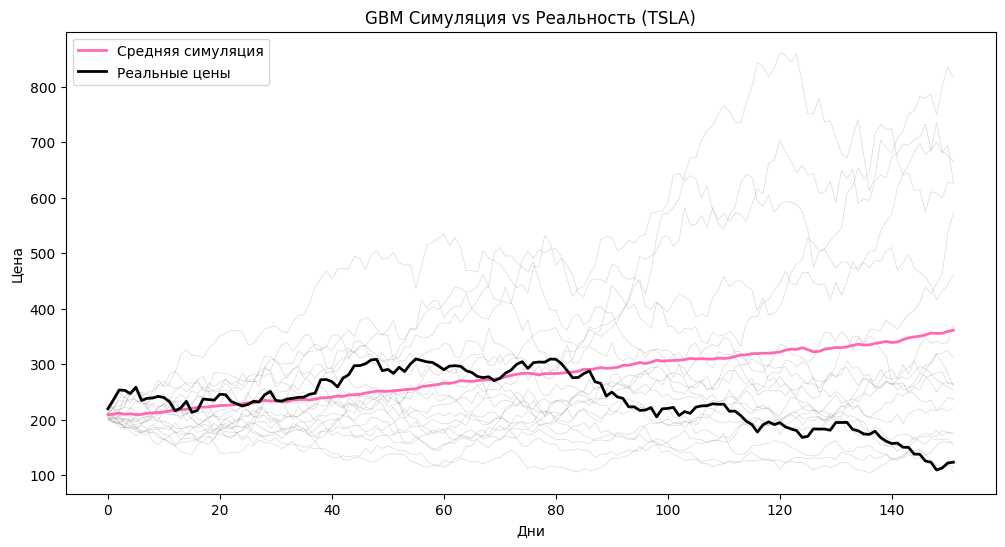

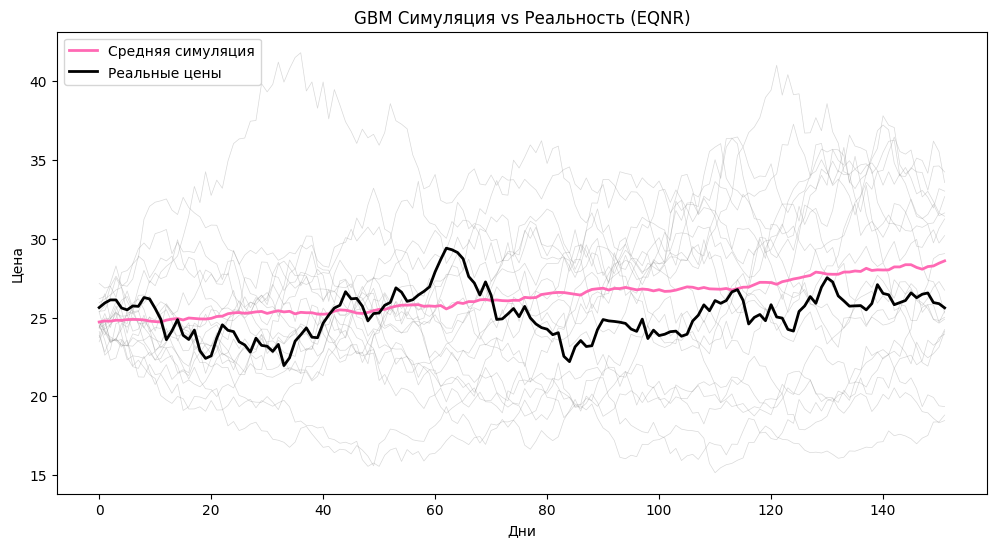

In [17]:
split_idx = int(len(data) * 0.8)
train_data = data.iloc[:split_idx]
test_data = data.iloc[split_idx:]
days_test = len(test_data)

def run_full_analysis(train_prices, test_prices, iterations=100):
    log_returns = np.log(train_prices / train_prices.shift(1)).dropna()
    mu = log_returns.mean()
    sigma = log_returns.std()
    S0 = train_prices.iloc[-1]
    days = len(test_prices)

    sims = []
    for _ in range(iterations):
        W = np.random.standard_normal(size=days)
        daily_returns = np.exp((mu - 0.5 * sigma**2) + sigma * W)
        price_path = [S0]
        for r in daily_returns:
            price_path.append(price_path[-1] * r)
        sims.append(price_path[1:])

    sims = np.array(sims)

    mse_list = []
    mape_list = []

    actual = test_prices.values

    for i in range(iterations):
        sim = sims[i]
        mse_list.append(mean_squared_error(actual, sim))
        mape_list.append(mean_absolute_percentage_error(actual, sim))

    return np.mean(mse_list), np.mean(mape_list), sims

mse_tsla, mape_tsla, sims_tsla = run_full_analysis(train_data['TSLA'], test_data['TSLA'])
mse_eqnr, mape_eqnr, sims_eqnr = run_full_analysis(train_data['EQNR'], test_data['EQNR'])

print(f"Результаты для TSLA (Test period: {days_test} days):")
print(f"Средний MSE: {mse_tsla:.2f}")
print(f"Средний MAPE: {mape_tsla:.2%}")

print(f"\nРезультаты для EQNR (Test period: {days_test} days):")
print(f"Средний MSE: {mse_eqnr:.2f}")
print(f"Средний MAPE: {mape_eqnr:.2%}")

def plot_simulations(sims, actual_prices, title):
    plt.figure(figsize=(12, 6))
    for i in range(min(20, sims.shape[0])):
        plt.plot(sims[i], color='gray', alpha=0.3, linewidth=0.5)

    plt.plot(np.mean(sims, axis=0), color='hotpink', label='Средняя симуляция', linewidth=2)

    plt.plot(actual_prices.values, color='black', label='Реальные цены', linewidth=2)

    plt.title(title)
    plt.legend()
    plt.xlabel('Дни')
    plt.ylabel('Цена')
    plt.show()

plot_simulations(sims_tsla, test_data['TSLA'], 'GBM Симуляция vs Реальность (TSLA)')
plot_simulations(sims_eqnr, test_data['EQNR'], 'GBM Симуляция vs Реальность (EQNR)')

Сравнение симулированных данных с реальными на тестовом периоде в 152 дня показало кардинальное различие в качестве модели GBM для двух активов. Для TSLA результаты оказались крайне неудовлетворительными: средняя абсолютная процентная ошибка (MAPE) составила 51.33%, а среднеквадратичная ошибка (MSE) достигла огромного значения 25034.46. На графике видно, что реальная цена ушла вниз, в то время как средняя симуляция предсказала рост, а «веер» серых линий оказался слишком широким. Модель GBM полностью не справилась с прогнозированием разворота тренда для высоковолатильного актива роста, подверженного резким шокам.

Для EQNR результаты оказались значительно лучше: ошибка MAPE составила 20.22%, что в 2.5 раза ниже, а MSE - всего 50.55. На графике реальная цена колеблется вокруг средней симуляции, и фактические данные большую часть времени находятся внутри плотного коридора серых линий. Таким образом, симуляция для Equinor является безусловно более надежной, так как стабильное поведение энергетического сектора лучше соответствует жестким математическим допущениям GBM о постоянной волатильности и логнормальном распределении доходностей, тогда как для TSLA классическая модель оказалась слишком примитивной.



**Итог**

**Временной ряд Tesla (TSLA):**
Для акций Tesla тест на единичный корень (ADF) показал p-value выше 0,05, что означает невозможность отвергнуть нулевую гипотезу - временной ряд является нестационарным и содержит случайное блуждание. Показатель Херста составил (H = 0.4626). Поскольку это значение меньше 0,5, ряд проявляет слабую антиперсистентность, то есть склонность к возврату к среднему, хотя и находится близко к зоне случайного блуждания. При симуляции цен с помощью геометрического броуновского движения (GBM) более 100 раз и последующем сравнении с реальными данными средняя абсолютная процентная ошибка (MAPE) составила 51.33%, а среднеквадратичная ошибка (MSE) - 25034.46. Столь высокая ошибка указывает на то, что классическая модель GBM плохо подходит для описания поведения TSLA. Высокая волатильность, тяжелые хвосты распределения и резкие смены трендов (шоки) не укладываются в жесткие допущения модели, из-за чего реальная цена может уходить далеко за пределы доверительного интервала симуляций.

**Временной ряд Equinor (EQNR):**
Для акций Equinor тест ADF также подтвердил нестационарность ряда (p-value > 0,05). Показатель Херста оказался существенно ниже 0,5 и составил (H = 0.3316). Это свидетельствует о ярко выраженной антиперсистентности: за периодами роста с высокой вероятностью следуют периоды падения. При симуляции GBM средний MAPE составил 20.22%, а MSE - 50.55, что в разы меньше, чем у Tesla. Это говорит о том, что модель GBM для Equinor является значительно более надежной. Более стабильное поведение энергетического сектора лучше соответствует допущениям модели о постоянной волатильности и логнормальном распределении доходностей, а реальные цены в большинстве случаев остаются внутри «веера» симулированных сценариев.

**Ответ на вопрос об инвестировании:**
Основываясь на результатах тестов и значении (H), для инвестирования предпочтительнее выбрать Equinor (EQNR). Сильная антиперсистентность делает этот актив привлекательным для контртрендовых стратегий (покупка на просадках, продажа на пиках), так как отклонения от среднего значения с высокой вероятностью будут скорректированы. TSLA с (H = 0.4626) находится в «серой зоне» ближе к случайному блужданию, что делает ее менее предсказуемой для статистических арбитражных стратегий. Кроме того, именно для EQNR симуляция GBM оказалась более надежной (MAPE 20.22% против 51.33%), что дополнительно подтверждает его статистическую предсказуемость.

**Практические соображения:**
Прежде чем применять эти интерпретации на практике, инвесторам следует также учесть следующие соображения:
*   Наблюдаемое значение H может меняться в разных временных рамках: проанализируйте H за период, соответствующий вашему инвестиционному горизонту.
*   Внешние факторы, такие как рыночные условия, экономические показатели и геополитические события, могут влиять на цены акций и должны рассматриваться наряду с H.
*   Независимо от значения H, реализация надлежащих стратегий управления рисками имеет важное значение для защиты от неожиданных движений рынка.
*   Если временной ряд слишком короткий, значение H может быть ненадежным (как в нашем случае с периодом в 3 года, который включал в себя аномальные рыночные шоки пандемии).